# EUV stochastics and flare

Notebook 152 (litho stochastics, flare and focus blur) built the
stochastic resist chain and the flare model with the wavelength as a
parameter, and compared ArF and EUV photons on 45 nm lines. This notebook
runs both at EUV, on EUV features:

- **The photon budget**: a 92 eV photon carries 14 times the energy of an
  ArF photon, and EUV resists are thin and absorb only a fraction of what
  arrives.
- **Rough 16 nm lines** imaged through the reflective mask of notebook 156 (EUV multilayers and reflective masks) at NA 0.33, in a chemically
  amplified resist (CAR) where each absorbed photon makes more than one
  acid. Which noise source dominates, how the roughness falls with the
  dose, the resolution, LWR and sensitivity trade-off (Z factor), and the
  **secondary electron blur** (`StochasticResist(electron_blur=...)`,
  new): the electrons that a 92 eV photon frees spread its acids over a
  few nanometres.
- **Contact holes**: local CD uniformity and missing holes against the
  dose, for a CAR and a resist that absorbs four times more.
- **Flare**: scatter grows as $1/\lambda^2$, so the mirrors of an EUV
  projector must be smoother than any DUV lens surface, and the flare level
  depends on the tone of the mask: a dark-field layer sees much less.

The NA 0.33 projector and the TaBN mask are those of notebook 156 (EUV multilayers and reflective masks); the high-NA pupils of notebook 157 (EUV projector and pupil) would change the images, not the counting.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import (Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, euv, flare,
                            metrics, resist, stochastics as st)

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
BLUE, ORANGE, GREEN, YELLOW, RED, PURPLE, GREY = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b",
                                                  "#8a5cc2", "#888888")
LAM = euv.EUV_WAVELENGTH

## 1. The photon budget

A dose of $D$ mJ/cm² delivers $D\cdot 10^{-17}/E_\mathrm{ph}$ photons per
nm², and a resist of thickness $d$ absorbs the fraction
$1 - e^{-\alpha d}$. EUV resists are thin (the depth of focus and pattern
collapse of 16 nm lines allow 30 to 40 nm) and organic ones absorb about
5/µm at 13.5 nm; resists with metals (tin, hafnium, zinc) absorb several
times more.

In [2]:
EV = 1.602176634e-19
print(f"photon energy: ArF {st.photon_energy(193.368)/EV:.1f} eV, EUV {st.photon_energy(LAM)/EV:.1f} eV")
print(f"photons per nm² and mJ/cm²: ArF {st.photons_per_area(1, 193.368):.2f}, EUV {st.photons_per_area(1, LAM):.2f}\n")
resists = {"ArF CAR, 90 nm, α = 1/µm": (193.368, 90.0, 1e-3),
           "EUV CAR, 35 nm, α = 5/µm": (LAM, 35.0, 5e-3),
           "EUV high absorption, 25 nm, α = 20/µm": (LAM, 25.0, 20e-3)}
print(f"{'resist':40s} {'absorbed':>9s}  {'photons absorbed in a 16 x 16 nm² square':>42s}")
for name, (lam, d, alpha) in resists.items():
    R = st.StochasticResist(wavelength=lam, thickness=d, absorption=alpha)
    dose = 30.0 if lam > 100 else 40.0
    n = R.absorbed_photons(dose, 16*16)
    print(f"{name:40s} {100*R.absorbed_fraction:7.1f} %   at {dose:.0f} mJ/cm²: {n:7.0f}, "
          f"Poisson noise {100/np.sqrt(n):4.1f} %")

photon energy: ArF 6.4 eV, EUV 91.8 eV
photons per nm² and mJ/cm²: ArF 9.73, EUV 0.68

resist                                    absorbed    photons absorbed in a 16 x 16 nm² square
ArF CAR, 90 nm, α = 1/µm                     8.6 %   at 30 mJ/cm²:    6435, Poisson noise  1.2 %
EUV CAR, 35 nm, α = 5/µm                    16.1 %   at 40 mJ/cm²:    1117, Poisson noise  3.0 %
EUV high absorption, 25 nm, α = 20/µm       39.3 %   at 40 mJ/cm²:    2738, Poisson noise  1.9 %


A 16 nm square of an EUV CAR absorbs about 1100 photons at 40 mJ/cm²,
six times fewer than an ArF resist at 30 mJ/cm² on a much larger feature
of its own. The Poisson noise of the dose in that square is 3 %,
before any chemistry. A resist that absorbs four times more per micrometre
gets 2.5 times more photons into a thinner film. This is the main reason
for metal-containing EUV resists.

## 2. Rough 16 nm lines

Lines and spaces at 32 nm pitch, NA 0.33, a dipole and the 60 nm TaBN
mask (RCWA, notebook 156, EUV multilayers and reflective masks). The
resist: 35 nm thick, α = 5/µm, 0.2 acid generator molecules per nm³, acid
diffusion 5 nm, quencher 15 %; sized to 16 nm with the mean chain. Cells of
0.25 nm² along a strip 1 µm long.

NILS of the aerial image 2.69; dose to size 37.7 mJ/cm²; 1.33 acids per absorbed photon in the open frame


Roughness(cd=16.09, ler=2.86, lwr=4.38, correlation=-0.17, broken=0.000)


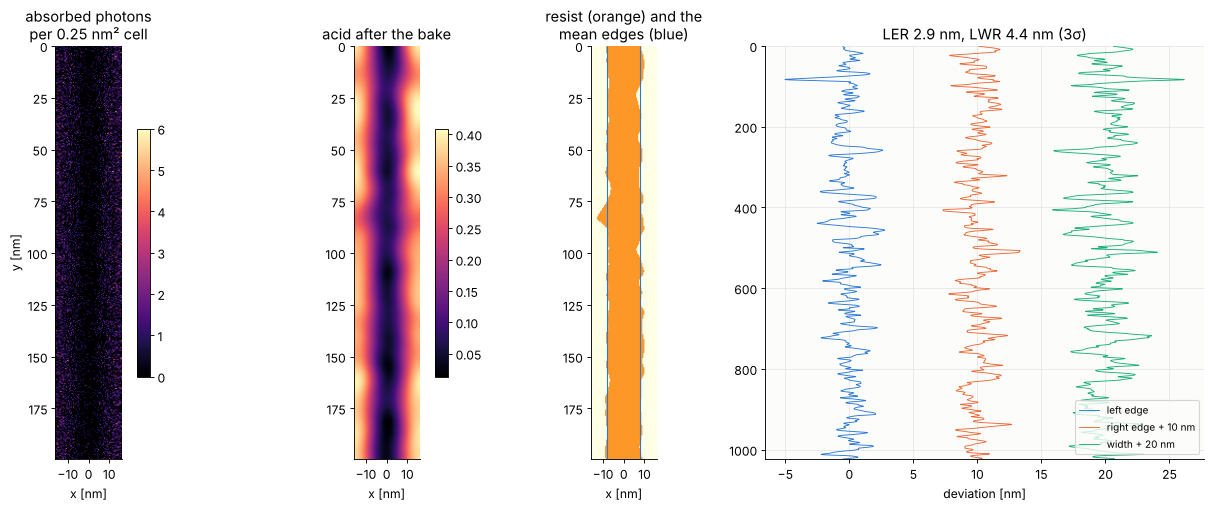

In [3]:
P = Projector(0.33, LAM, magnification=4)
mask = euv.ReflectiveMask([("TaBN", 60.0)])
lines = LithoSimulation(MaskLayout.lines_spaces(32.0, 16.0), mask,
                        Illumination.dipole(0.9, 0.55, axis="x", n_samples=21), P)
dx = 0.5
x = np.arange(-16.0, 16.0, dx)
y = np.arange(0.0, 1024.0, dx)
I_line = lines.image(x)
I2 = np.tile(I_line, (len(y), 1))
model = resist.ResistModel(C=0.04, diffusion_length=5.0, amplification=3.0, quencher=0.15,
                           quencher_diffusion_length=3.0, n_steps=20)
car = st.StochasticResist(model, wavelength=LAM, thickness=35.0, absorption=5e-3, pag=0.2, blocking=2.0,
                          development_length=1.5)
D_car = car.dose_to_size(x, I_line, 16.0)
print(f"NILS of the aerial image {lines.nils(threshold=0.3):.2f}; dose to size {D_car:.1f} mJ/cm²; "
      f"{car.acid_yield(1.0, D_car, 1.0):.2f} acids per absorbed photon in the open frame")
res = car.process(I2, D_car, dx, rng=1)
mean = car.mean(I2, D_car, dx)
left, right = st.line_edges(x, res.m, model.m_th)
rough = st.roughness(left, right)
print(rough)

fig, axes = plt.subplots(1, 4, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
show = slice(0, 400)
ext = (x[0], x[-1] + dx, y[show][-1], y[0])
im = axes[0].imshow(res.photons[show], extent=ext, aspect="equal", cmap="magma")
axes[0].set_title("absorbed photons\nper 0.25 nm² cell")
fig.colorbar(im, ax=axes[0], shrink=0.6)
im = axes[1].imshow(res.acid[show], extent=ext, aspect="equal", cmap="magma")
axes[1].set_title("acid after the bake")
fig.colorbar(im, ax=axes[1], shrink=0.6)
axes[2].imshow(res.m[show] >= model.m_th, extent=ext, aspect="equal", cmap="YlOrBr", vmax=2)
axes[2].contour(x, y[show], mean.m[show], [model.m_th], colors=[BLUE], linewidths=1.0)
axes[2].set_title("resist (orange) and the\nmean edges (blue)")
for ax in axes[:3]:
    ax.set_xlabel("x [nm]"); ax.grid(False)
axes[0].set_ylabel("y [nm]")
ax = axes[3]
ax.plot(left - np.nanmean(left), y, color=BLUE, lw=0.8, label="left edge")
ax.plot(right - np.nanmean(right) + 10, y, color=ORANGE, lw=0.8, label="right edge + 10 nm")
ax.plot(right - left - np.nanmean(right - left) + 20, y, color=GREEN, lw=0.8, label="width + 20 nm")
ax.set_ylim(y[-1], 0); ax.set_xlabel("deviation [nm]"); ax.legend(fontsize=9, loc="lower right")
ax.set_title(f"LER {rough.ler:.1f} nm, LWR {rough.lwr:.1f} nm (3σ)")
fig.tight_layout()

At 38 mJ/cm² a cell of 0.25 nm² absorbs about one photon in the open
frame and 0.6 at the peak of the image: most cells hold none or one, a
few up to five. The bake spreads the acids over the diffusion length and leaves
edges with an LER of about 3 nm and an LWR of about 4 nm (3σ), a quarter of
the CD. Real EUV processes reach 2.5 to 3.5 nm LWR at this pitch with
optimized resists and etch smoothing.

Each absorbed photon makes 1.3 acids on average (the secondary electrons
of a 92 eV photon can activate several acid generator molecules). Which
counts set the roughness:

LWR [nm]: photons 2.95, acid 2.08, photons + acid 3.49, quencher 1.25, deprotection 1.17, all 4.00


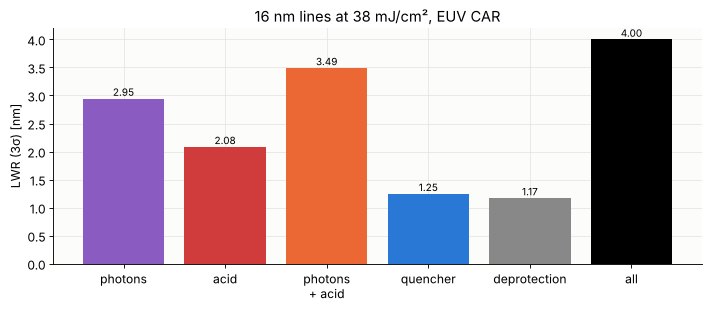

In [4]:
sources = [("photon",), ("acid",), ("photon", "acid"), ("quencher",), ("deprotection",), st.NOISE_SOURCES]
labels = ["photons", "acid", "photons\n+ acid", "quencher", "deprotection", "all"]
I_s = I2[:1024]
lwr = []
for src in sources:
    Rs = car.with_(noise=src)
    lwr.append(np.mean([st.roughness(*st.line_edges(x, Rs.process(I_s, D_car, dx, rng=s).m,
                                                     model.m_th)).lwr for s in range(4)]))
lwr = np.array(lwr)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, lwr, color=[PURPLE, RED, ORANGE, BLUE, GREY, "k"])
ax.set_ylabel("LWR (3σ) [nm]")
ax.set_title(f"16 nm lines at {D_car:.0f} mJ/cm², EUV CAR")
print("LWR [nm]:", ", ".join(f"{l.replace(chr(10), ' ')} {v:.2f}" for l, v in zip(labels, lwr)))
for i, v in enumerate(lwr):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
fig.tight_layout()

At EUV the photons are the largest single source, unlike ArF in notebook
152 (litho stochastics, flare and focus blur), where the acids were. With
more than one acid per photon the acid count is no longer a thinned subset
of the photons, so the photon noise passes on to the acid in full and the
acid statistics add to it.

## 3. Dose, absorption and the RLS trade-off

LWR against the dose, with the Dill C scaled so that the mean chain (and
the printed CD) stays the same: more photons, the same chemistry. Then
the secondary electron blur at the nominal dose.

EUV CAR, α = 5/µm LWR: 19: 5.14 26: 4.54 38: 3.94 53: 3.43 75: 2.94 105: 2.35 151: 2.56


high absorption, α = 20/µm, 25 nm LWR: 19: 3.63 26: 3.27 38: 2.92 53: 2.44 75: 2.82 105: 2.51 151: 2.60
42 runs in 4 s
EUV CAR, α = 5/µm: LWR 3.94 nm at 38 mJ/cm², Z = R³ LWR² D = 2.39e-08 mJ nm³
high absorption, α = 20/µm, 25 nm: LWR 2.92 nm at 38 mJ/cm², Z = R³ LWR² D = 1.32e-08 mJ nm³


electron blur 0 nm: dose to size 37.7 mJ/cm², LWR 4.01 nm, deprotection slope 0.059/nm
electron blur 1 nm: dose to size 37.8 mJ/cm², LWR 3.95 nm, deprotection slope 0.058/nm
electron blur 2 nm: dose to size 38.1 mJ/cm², LWR 3.83 nm, deprotection slope 0.055/nm
electron blur 3 nm: dose to size 38.3 mJ/cm², LWR 3.82 nm, deprotection slope 0.050/nm
electron blur 4 nm: dose to size 38.5 mJ/cm², LWR 4.25 nm, deprotection slope 0.044/nm
electron blur 6 nm: dose to size 38.7 mJ/cm², LWR 6.22 nm, deprotection slope 0.030/nm


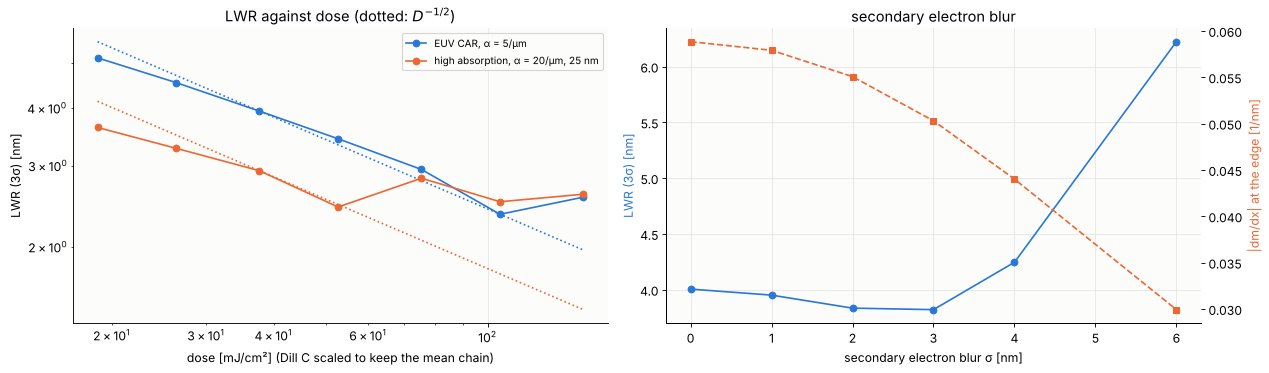

In [5]:
factors = np.array([0.5, 0.7, 1.0, 1.4, 2.0, 2.8, 4.0])
curves = {}
t0 = time.time()
for name, R in (("EUV CAR, α = 5/µm", car),
                ("high absorption, α = 20/µm, 25 nm", car.with_(absorption=20e-3, thickness=25.0, pag=0.28))):
    D0 = R.dose_to_size(x, I_line, 16.0)
    vals = []
    for f in factors:
        Rf = R.with_(model=model.with_(C=model.C/f))      # the same mean chain at f times the dose
        vals.append(np.mean([st.roughness(*st.line_edges(x, Rf.process(I_s, f*D0, dx, rng=20 + s).m,
                                                          model.m_th)).lwr for s in range(3)]))
    curves[name] = (factors*D0, np.array(vals), D0)
    print(name, "LWR:", " ".join(f"{d:.0f}: {v:.2f}" for d, v in zip(factors*D0, vals)))
print(f"{len(curves)*len(factors)*3} runs in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax = axes[0]
for (name, (D, v, D0)), col in zip(curves.items(), (BLUE, ORANGE)):
    ax.loglog(D, v, "o-", color=col, label=name)
    ax.loglog(D, v[2]*np.sqrt(D[2]/D), ":", color=col)
    z = euv.z_factor(16.0, v[2], D[2])
    print(f"{name}: LWR {v[2]:.2f} nm at {D[2]:.0f} mJ/cm², Z = R³ LWR² D = {z:.2e} mJ nm³")
ax.set_xlabel("dose [mJ/cm²] (Dill C scaled to keep the mean chain)"); ax.set_ylabel("LWR (3σ) [nm]")
ax.legend(fontsize=9); ax.set_title("LWR against dose (dotted: $D^{-1/2}$)")

blurs = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 6.0])
lwr_b, nils_b, dose_b = [], [], []
for b in blurs:
    Rb = car.with_(electron_blur=b)
    Db = Rb.dose_to_size(x, I_line, 16.0)
    m_mean = Rb.mean(I_line[None, :], Db, dx).m[0]
    lwr_b.append(np.mean([st.roughness(*st.line_edges(x, Rb.process(I_s, Db, dx, rng=40 + s).m,
                                                       model.m_th)).lwr for s in range(3)]))
    slope = np.abs(np.interp(-8.0, x[:-1] + dx/2, np.diff(m_mean)/dx))
    nils_b.append(slope); dose_b.append(Db)
ax = axes[1]
ax.plot(blurs, lwr_b, "o-", color=BLUE)
ax.set_xlabel("secondary electron blur σ [nm]"); ax.set_ylabel("LWR (3σ) [nm]", color=BLUE)
ax2 = ax.twinx()
ax2.plot(blurs, nils_b, "s--", color=ORANGE)
ax2.set_ylabel("|dm/dx| at the edge [1/nm]", color=ORANGE); ax2.grid(False)
ax.set_title("secondary electron blur")
fig.tight_layout()
for b, l, s_, d in zip(blurs, lwr_b, nils_b, dose_b):
    print(f"electron blur {b:.0f} nm: dose to size {d:.1f} mJ/cm², LWR {l:.2f} nm, deprotection slope {s_:.3f}/nm")

Up to about 50 mJ/cm² the LWR falls as $D^{-1/2}$ (dotted): the shot
noise of the photons sets it. Doubling the dose takes LWR from 3.9 to 2.9
nm, but halves the throughput of a scanner whose source is the expensive
part. Above that the curves level off at about 2.5 nm, where the counts
of quencher and protecting groups, which do not grow with the dose, take
over (three strips of 0.5 µm per point leave some scatter). The resist
that absorbs 20/µm is better at half the dose than the CAR at the full one. The Z
factor $Z = R^3\,\mathrm{LWR}^2 D$ (Wallow et al.) bundles resolution
(half pitch), roughness and dose into one number for a resist platform:
2.4·10⁻⁸ mJ·nm³ for the CAR, 1.3·10⁻⁸ for the absorbing resist, the
range of published EUV resists. At fixed Z, 20 % less LWR costs 56 % more
dose.

A secondary electron blur of 1 to 3 nm (realistic values) changes little:
it averages the acids of one photon over a few nanometres, which helps the
LWR slightly, and flattens the deprotection at the edge, which hurts. At
4 to 6 nm the flatter edge wins and the LWR rises, the blur acting like a
too long acid diffusion.

## 4. Contact holes

24 nm holes at 48 nm pitch (bright holes in a dark field, a thin binary
mask here since `ReflectiveMask` is for 1D layouts), a quasar source, 12 ×
12 holes and three seeds per dose. The two resists of section 3.

7776 holes in 21 s
EUV CAR: dose to size 54.2 mJ/cm², LCDU 3.1 nm at that dose
high absorption: dose to size 54.2 mJ/cm², LCDU 2.1 nm at that dose


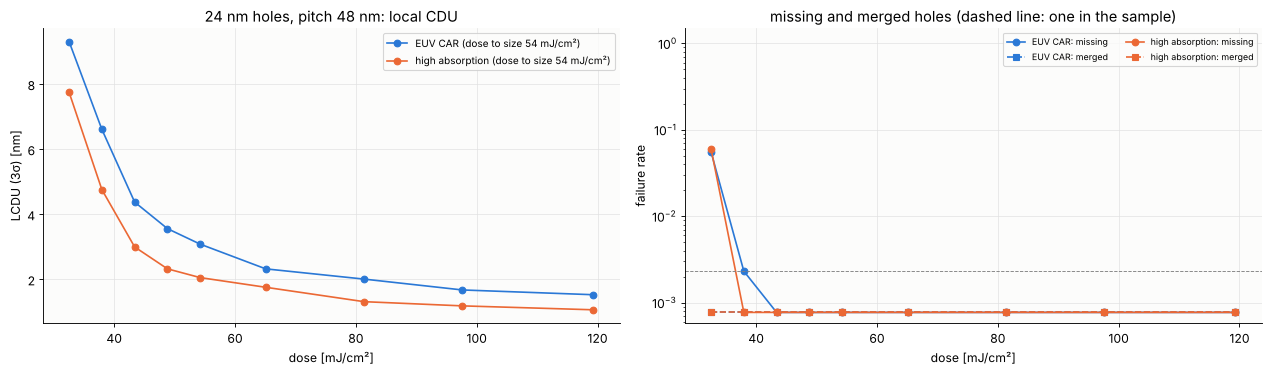

In [6]:
p_c = 48.0
contacts = LithoSimulation(MaskLayout.contact_holes(p_c, 24.0), ThinMask.binary(),
                           Illumination.quasar(0.9, 0.6, n_samples=15), P)
dxc = 1.0
n_c = 12
xc = np.arange(-p_c/2, -p_c/2 + n_c*p_c, dxc)
I_c = contacts.image(xc, xc)
n_p = int(p_c/dxc)
stats = {}
t0 = time.time()
for name, R in (("EUV CAR", car), ("high absorption", car.with_(absorption=20e-3, thickness=25.0, pag=0.28))):
    D_c = R.dose_to_size(xc[:n_p], I_c[n_p//2, :n_p], 24.0, feature="space")
    fs = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.5, 1.8, 2.2])
    out = []
    for f in fs:
        ss = [st.contact_stats(xc, xc, R.process(I_c, f*D_c, dxc, rng=100 + k).cleared, p_c) for k in range(3)]
        cd = np.concatenate([s.cd[s.good] for s in ss])
        out.append((np.mean([s.missing_rate for s in ss]), np.mean([s.merged_rate for s in ss]),
                    np.mean(cd) if len(cd) else np.nan, 3*np.std(cd) if len(cd) > 1 else np.nan))
    stats[name] = (fs*D_c, np.array(out), D_c)
print(f"{2*len(fs)*3*n_c**2} holes in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
floor = 1/(3*n_c**2)
for (name, (D, s, D_c)), col in zip(stats.items(), (BLUE, ORANGE)):
    axes[0].plot(D, s[:, 3], "o-", color=col, label=f"{name} (dose to size {D_c:.0f} mJ/cm²)")
    axes[1].semilogy(D, np.maximum(s[:, 0], floor/3), "o-", color=col, label=f"{name}: missing")
    axes[1].semilogy(D, np.maximum(s[:, 1], floor/3), "s--", color=col, label=f"{name}: merged")
    print(f"{name}: dose to size {D_c:.1f} mJ/cm², LCDU {s[4, 3]:.1f} nm at that dose")
axes[0].set_xlabel("dose [mJ/cm²]"); axes[0].set_ylabel("LCDU (3σ) [nm]"); axes[0].legend(fontsize=9)
axes[0].set_title("24 nm holes, pitch 48 nm: local CDU")
axes[1].axhline(floor, color="0.5", lw=0.8, ls="--")
axes[1].set_ylim(floor/4, 1.5); axes[1].set_xlabel("dose [mJ/cm²]"); axes[1].set_ylabel("failure rate")
axes[1].legend(fontsize=8, ncol=2); axes[1].set_title("missing and merged holes (dashed line: one in the sample)")
fig.tight_layout()

Below the nominal dose the local CDU grows fast (9 nm at 60 % of the dose
against 3 nm at the nominal 54 mJ/cm²), and at 60 % of the dose about 5 %
of the holes stay closed: the stochastic cliff of notebook 152 (litho stochastics, flare and focus blur), here at EUV doses. The absorbing
resist cuts the LCDU by a third at every dose. A chip has 10¹⁰ holes per
layer, so the failure rates that matter (below 10⁻¹⁰) lie far beyond
what a sample of 432 holes can show: the dose is set with a margin and
the tails of the CD distribution are measured (De Bisschop).

## 5. Flare

The total integrated scatter of a mirror is $(4\pi\sigma/\lambda)^2$:
0.1 nm of roughness, harmless on a DUV lens surface, scatters 0.9 % per
EUV mirror. Six mirrors with 0.1 nm give 5 % flare; for 2 % each mirror
needs a roughness of about 60 pm over the spatial periods that scatter into
the flare range (1 µm to 1 mm), polished at the limits of what is
possible. The flare level is the total times the pattern density around
the point, blurred over the reach of the PSF (`Flare.level_map()`); a die
with a memory block, logic and a clear scribe line, once as a bright-field
layer (lines, 35 to 50 % open) and once as a dark-field layer (contact
holes, 6 to 12 % open):

TIS of 0.1 nm: a fused silica surface at 193 nm 0.0003 %, a mirror at 13.5 nm 0.87 % (x2617)
6 mirrors: 5.2 % flare at 0.1 nm; 2 % needs σ ≤ 62 pm per mirror
10 mirrors: 8.7 % flare at 0.1 nm; 2 % needs σ ≤ 48 pm per mirror
EUV projector, 6 mirrors of 60 pm: Flare(total=0.01872, r_min=270, r_max=2.7e+05)
16 nm lines: -0.36 nm of CD per % of flare level, NILS 2.62 -> 2.44 at 3 %
bright-field layer (lines): flare level in the die 0.66 to 0.94 % (mean 0.74 %)
dark-field layer (contacts): flare level in the die 0.11 to 0.23 % (mean 0.15 %)


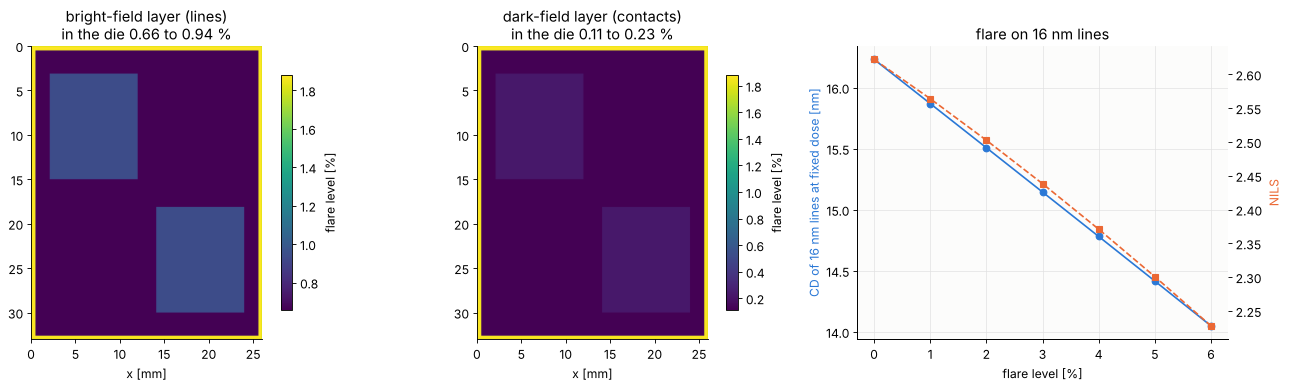

In [7]:
psd = flare.ABCRoughness(sigma=0.1, B=2e5, C=1.6, f_min=1e-6, f_max=1e-3)   # 0.1 nm, periods 1 µm to 1 mm
L_arm = 2e7
print(f"TIS of 0.1 nm: a fused silica surface at 193 nm {100*flare.tis(0.1, 193.368, 1.56):.4f} %, "
      f"a mirror at 13.5 nm {100*flare.tis(0.1, LAM):.2f} % (x{flare.tis(0.1, LAM)/flare.tis(0.1, 193.368, 1.56):.0f})")
for n_m in (6, 10):
    sigma_2 = LAM/(4*np.pi)*np.sqrt(0.02/n_m)
    print(f"{n_m} mirrors: {100*n_m*flare.tis(0.1, LAM):.1f} % flare at 0.1 nm; 2 % needs σ ≤ {1e3*sigma_2:.0f} pm per mirror")
F_euv = flare.Flare.from_roughness(psd.__class__(0.06, 2e5, 1.6, 1e-6, 1e-3), LAM, L_arm, n_surfaces=6)
print("EUV projector, 6 mirrors of 60 pm:", F_euv)

x_l = np.arange(-16.0, 16.0, 0.25)
I_l = lines.image(x_l)
th0 = 0.3
dose0 = metrics.dose_to_size(x_l, I_l, 16.0, threshold=th0)
levels = np.linspace(0, 0.06, 7)
cd_l = [metrics.threshold_cd(x_l, dose0*((1 - F_euv.total)*I_l + lev), th0) for lev in levels]
nils_l = [metrics.nils_at_threshold(x_l, dose0*((1 - F_euv.total)*I_l + lev), th0) for lev in levels]
slope_cd = np.polyfit(100*levels, cd_l, 1)[0]
print(f"16 nm lines: {slope_cd:+.2f} nm of CD per % of flare level, NILS {nils_l[0]:.2f} -> {nils_l[3]:.2f} at 3 %")

# a die: memory (dense lines, 50 % open), logic (35 %), a dark-field contact layer (8 %), clear scribe
dxd = 0.1e6
Xd, Yd = np.meshgrid(np.arange(0, 26e6, dxd), np.arange(0, 33e6, dxd))
bright = np.full(Xd.shape, 0.35)
bright[(Xd > 2e6) & (Xd < 12e6) & (Yd > 3e6) & (Yd < 15e6)] = 0.5
bright[(Xd > 14e6) & (Xd < 24e6) & (Yd > 18e6) & (Yd < 30e6)] = 0.5
bright[(Xd < 0.5e6) | (Xd > 25.5e6) | (Yd < 0.5e6) | (Yd > 32.5e6)] = 1.0
dark = np.where(bright == 1.0, 1.0, np.where(bright == 0.5, 0.12, 0.06))
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))
for ax, dens, title in ((axes[0], bright, "bright-field layer (lines)"), (axes[1], dark, "dark-field layer (contacts)")):
    lev = F_euv.level_map(dens, dxd)
    die = lev[bright < 1.0]
    im = ax.imshow(100*lev, extent=(0, 26, 33, 0), cmap="viridis")
    fig.colorbar(im, ax=ax, shrink=0.8, label="flare level [%]")
    ax.set_title(f"{title}\nin the die {100*die.min():.2f} to {100*die.max():.2f} %"); ax.grid(False)
    ax.set_xlabel("x [mm]")
    print(f"{title}: flare level in the die {100*die.min():.2f} to {100*die.max():.2f} % "
          f"(mean {100*die.mean():.2f} %)")
axes[2].plot(100*levels, cd_l, "o-", color=BLUE)
axes[2].set_xlabel("flare level [%]"); axes[2].set_ylabel("CD of 16 nm lines at fixed dose [nm]", color=BLUE)
a2 = axes[2].twinx(); a2.plot(100*levels, nils_l, "s--", color=ORANGE); a2.grid(False)
a2.set_ylabel("NILS", color=ORANGE)
axes[2].set_title("flare on 16 nm lines")
fig.tight_layout()

With 6 mirrors of 60 pm (1.9 % total) the bright-field layer sees 0.7 to
0.9 % flare, the dark-field layer only 0.1 to 0.2 %: EUV layers are printed
dark-field where the tone allows it, and the flare of bright-field layers
is corrected with the density map in the OPC (flare-aware OPC). For 16 nm
lines each percent of flare takes 0.36 nm off the dark lines and costs
NILS; the 0.3 % variation across this die is 0.1 nm, small next to the 4 nm
of LWR.

## 6. Summary

- At 13.5 nm a photon carries 92 eV, and a 16 nm square of a 35 nm CAR
  absorbs about a thousand of them at 40 mJ/cm² (3 % Poisson noise).
  Absorbing (metal-containing) resists take in 2.5 times more.
- 16 nm lines through the rigorous EUV mask print with about 3 nm LER and
  4 nm LWR at 38 mJ/cm². Photon shot noise is the largest source, and
  with 1.3 acids per photon the photon noise reaches the acid in full.
  LWR falls as $D^{-1/2}$; the RLS trade-off gives Z ≈ 2·10⁻⁸ mJ·nm³ for the
  CAR, 1.3·10⁻⁸ for the absorbing resist. Secondary electron blur of a few
  nanometres changes little; more acts like excess diffusion.
- 24 nm contact holes: LCDU of 3 nm at the nominal dose, failures below
  70 % of it; the absorbing resist lowers the LCDU by a third.
- Flare grows as $1/\lambda^2$: 2 % from six mirrors needs 60 pm of
  roughness. The level follows the pattern density, so dark-field layers
  see a fifth of the flare of bright-field ones.
- New in the code: `StochasticResist(electron_blur=...)` and
  `euv.z_factor()`; everything else is the chain of notebook 152 (litho stochastics, flare and focus blur) with EUV numbers.

In [8]:
print(f"run time {time.time() - t_start:.0f} s")

run time 32 s
